# Facial Emotion Recognition — Kaggle Training Notebook (RAF-DB)

Trains a CNN on 48×48 grayscale face images across **7 emotion classes** using the RAF-DB dataset.

**Output:** `facialemotionmodel.h5` saved to `/kaggle/working/`

### Before running:
1. Settings (right panel) → **Accelerator** → **GPU T4 x2**
2. Add your RAF-DB dataset via the **Data** tab on the right
3. Update `DATASET_NAME` in Step 1 to match your dataset slug
4. Click **Save Version** → **Save & Run All (Commit)** to train offline

## Step 1 — Configuration

In [1]:
import os

# ── UPDATE THIS to match your dataset slug shown in the Data tab ─────────────
DATASET_NAME = 'raf-db-dataset'  # <-- change this

# Paths
INPUT_DIR  = f'/kaggle/input/datasets/shuvoalok/raf-db-dataset'
OUTPUT_DIR = '/kaggle/working'

# RAF-DB structure: DATASET/train/1..7 and DATASET/test/1..7
# Auto-detect root folder
TRAIN_DIR = None
TEST_DIR  = None
TRAIN_CSV = None
TEST_CSV  = None

for subfolder in ['DATASET', 'dataset', '']:
    base = os.path.join(INPUT_DIR, subfolder) if subfolder else INPUT_DIR
    candidate_train = os.path.join(base, 'train')
    candidate_test  = os.path.join(base, 'test')
    candidate_train_csv = os.path.join(base, 'train_labels.csv')
    candidate_test_csv  = os.path.join(base, 'test_labels.csv')
    if os.path.exists(candidate_train):
        TRAIN_DIR = candidate_train
        TEST_DIR  = candidate_test
        TRAIN_CSV = candidate_train_csv if os.path.exists(candidate_train_csv) else None
        TEST_CSV  = candidate_test_csv  if os.path.exists(candidate_test_csv)  else None
        break

print('Train dir :', TRAIN_DIR, '— exists:', os.path.exists(TRAIN_DIR))
print('Test  dir :', TEST_DIR,  '— exists:', os.path.exists(TEST_DIR))
print('Train CSV :', TRAIN_CSV)
print('Test  CSV :', TEST_CSV)
print('Output dir:', OUTPUT_DIR)

print('\nAvailable datasets in /kaggle/input/:')
for d in os.listdir('/kaggle/input'):
    print(' ', d)

print('\nTrain subfolders:', sorted(os.listdir(TRAIN_DIR)))
print('Test  subfolders:', sorted(os.listdir(TEST_DIR)))

Train dir : /kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/train — exists: True
Test  dir : /kaggle/input/datasets/shuvoalok/raf-db-dataset/DATASET/test — exists: True
Train CSV : None
Test  CSV : None
Output dir: /kaggle/working

Available datasets in /kaggle/input/:
  datasets

Train subfolders: ['1', '2', '3', '4', '5', '6', '7']
Test  subfolders: ['1', '2', '3', '4', '5', '6', '7']


## Step 2 — Check GPU

In [2]:
import tensorflow as tf

print('TensorFlow version:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs available:', gpus)

if gpus:
    print('✅ GPU detected — training will be fast!')
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
else:
    print('⚠️  No GPU detected. Go to Settings → Accelerator → GPU T4 x2')

2026-03-20 11:59:18.126107: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774007958.314831      24 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774007958.371070      24 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774007958.827391      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774007958.827435      24 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774007958.827438      24 computation_placer.cc:177] computation placer alr

TensorFlow version: 2.19.0
GPUs available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
✅ GPU detected — training will be fast!


## Step 3 — Imports

In [3]:
import glob
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from tensorflow.keras.preprocessing.image import load_img, ImageDataGenerator
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import (
    Dense, Conv2D, Dropout, Flatten,
    MaxPooling2D, BatchNormalization
)
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.optimizers import Adam

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
print('All imports successful.')

All imports successful.


## Step 4 — Build Dataset Dataframes

RAF-DB uses numbered folders (1–7). We read the CSV label files to get the
exact image filename → label mapping, then locate each image in the numbered
subfolders. This ensures we use the correct label for every image.

In [4]:
# RAF-DB standard label mapping: folder number → emotion name
RAFDB_LABELS = {
    1: 'surprise',
    2: 'fear',
    3: 'disgust',
    4: 'happy',
    5: 'sad',
    6: 'angry',
    7: 'neutral'
}

def build_dataframe_from_csv(csv_path, img_dir):
    """
    Reads the CSV (columns: image, label) and builds a dataframe with
    full image paths and emotion name labels.
    The image is located inside img_dir/<label_number>/<image_name>
    """
    df = pd.read_csv(csv_path)
    print(f'CSV columns: {list(df.columns)}')
    print(f'CSV sample:\n{df.head(3)}')

    # Normalise column names to lowercase
    df.columns = [c.strip().lower() for c in df.columns]

    image_paths, labels = [], []
    missing = 0

    for _, row in df.iterrows():
        img_name  = str(row['image']).strip()
        label_num = int(row['label'])
        emotion   = RAFDB_LABELS.get(label_num, str(label_num))

        # Image lives in img_dir/<label_number>/<image_name>
        img_path = os.path.join(img_dir, str(label_num), img_name)

        if os.path.exists(img_path):
            image_paths.append(img_path)
            labels.append(emotion)
        else:
            missing += 1

    print(f'Loaded: {len(image_paths)} images, missing: {missing}')
    return image_paths, labels


def build_dataframe_from_folders(img_dir):
    """
    Fallback: scan numbered subfolders directly if no CSV is available.
    """
    image_paths, labels = [], []
    for folder in sorted(os.listdir(img_dir)):
        folder_path = os.path.join(img_dir, folder)
        if not os.path.isdir(folder_path):
            continue
        emotion = RAFDB_LABELS.get(int(folder), folder) if folder.isdigit() else folder
        count = 0
        for imagename in os.listdir(folder_path):
            if imagename.lower().endswith(('.jpg', '.jpeg', '.png')):
                image_paths.append(os.path.join(folder_path, imagename))
                labels.append(emotion)
                count += 1
        print(f'  folder {folder} ({emotion}): {count} images')
    return image_paths, labels


# Build train dataframe
print('Building train dataframe...')
if TRAIN_CSV:
    train_images, train_labels = build_dataframe_from_csv(TRAIN_CSV, TRAIN_DIR)
else:
    print('No CSV found — using folder structure')
    train_images, train_labels = build_dataframe_from_folders(TRAIN_DIR)

train_df = pd.DataFrame({'image': train_images, 'label': train_labels})

# Build test dataframe
print('\nBuilding test dataframe...')
if TEST_CSV:
    test_images, test_labels = build_dataframe_from_csv(TEST_CSV, TEST_DIR)
else:
    print('No CSV found — using folder structure')
    test_images, test_labels = build_dataframe_from_folders(TEST_DIR)

test_df = pd.DataFrame({'image': test_images, 'label': test_labels})

print('\n── Summary ──────────────────────────')
print('Train samples:', len(train_df))
print('Test  samples:', len(test_df))
print('Classes:', sorted(train_df['label'].unique()))
print('\nTrain class distribution:')
print(train_df['label'].value_counts().sort_index())

Building train dataframe...
No CSV found — using folder structure
  folder 1 (surprise): 1290 images
  folder 2 (fear): 281 images
  folder 3 (disgust): 717 images
  folder 4 (happy): 4772 images
  folder 5 (sad): 1982 images
  folder 6 (angry): 705 images
  folder 7 (neutral): 2524 images

Building test dataframe...
No CSV found — using folder structure
  folder 1 (surprise): 329 images
  folder 2 (fear): 74 images
  folder 3 (disgust): 160 images
  folder 4 (happy): 1185 images
  folder 5 (sad): 478 images
  folder 6 (angry): 162 images
  folder 7 (neutral): 680 images

── Summary ──────────────────────────
Train samples: 12271
Test  samples: 3068
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Train class distribution:
label
angry        705
disgust      717
fear         281
happy       4772
neutral     2524
sad         1982
surprise    1290
Name: count, dtype: int64


## Step 5 — Extract Features & Normalise

In [5]:
def extract_features(images):
    features = []
    for image in tqdm(images):
        img = load_img(image, color_mode='grayscale', target_size=(48, 48))
        features.append(np.array(img))
    return np.array(features).reshape(-1, 48, 48, 1)

print('Extracting train features...')
x_train = extract_features(train_df['image']) / 255.0

print('Extracting test features...')
x_test = extract_features(test_df['image']) / 255.0

print('x_train shape:', x_train.shape)
print('x_test  shape:', x_test.shape)

Extracting train features...


100%|██████████| 12271/12271 [00:58<00:00, 208.00it/s]


Extracting test features...


100%|██████████| 3068/3068 [00:15<00:00, 203.37it/s]

x_train shape: (12271, 48, 48, 1)
x_test  shape: (3068, 48, 48, 1)


## Step 6 — Encode Labels

In [6]:
le = LabelEncoder()
le.fit(train_df['label'])

y_train = to_categorical(le.transform(train_df['label']), num_classes=7)
y_test  = to_categorical(le.transform(test_df['label']),  num_classes=7)

print('Label classes (index order used by model):', list(le.classes_))
print('y_train shape:', y_train.shape)

# Save label order — test_model.py must use this same order
with open(os.path.join(OUTPUT_DIR, 'label_classes.json'), 'w') as f:
    json.dump(list(le.classes_), f)
print('Label classes saved to label_classes.json')

Label classes (index order used by model): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
y_train shape: (12271, 7)
Label classes saved to label_classes.json


## Step 7 — Data Augmentation

In [7]:
datagen = ImageDataGenerator(
    horizontal_flip=True,
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    fill_mode='nearest'
)

datagen.fit(x_train)
print('Data augmentation configured.')

Data augmentation configured.


## Step 8 — Build or Resume Model

In [8]:
checkpoint_dir = os.path.join(OUTPUT_DIR, 'checkpoints')
os.makedirs(checkpoint_dir, exist_ok=True)

checkpoint_files = glob.glob(os.path.join(checkpoint_dir, '*.h5'))
start_epoch = 0

if checkpoint_files:
    latest_checkpoint = max(checkpoint_files, key=os.path.getmtime)
    print('Resuming from:', latest_checkpoint)
    model = load_model(latest_checkpoint, compile=False)
    model.compile(
        optimizer=Adam(learning_rate=1e-4),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    match = re.search(r'facialemotionmodel(\d+)_', os.path.basename(latest_checkpoint))
    if match:
        start_epoch = int(match.group(1))
    print('Resuming from epoch:', start_epoch)

else:
    print('No checkpoint found — building model from scratch')
    model = Sequential([
        tf.keras.layers.Input(shape=(48, 48, 1)),

        Conv2D(64,  (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 24×24
        Dropout(0.3),

        Conv2D(128, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 12×12
        Dropout(0.3),

        Conv2D(256, (3, 3), padding='same', activation='relu'),
        BatchNormalization(),
        MaxPooling2D((2, 2)),   # → 6×6
        Dropout(0.3),

        Flatten(),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.5),
        Dense(256, activation='relu'),
        Dropout(0.4),
        Dense(7, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=1e-3),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

model.summary()

No checkpoint found — building model from scratch


I0000 00:00:1774008059.236355      24 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     4,719,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,225,735 (19.93 MB)

 Trainable params: 5,223,815 (19.93 MB)

 Non-trainable params: 1,920 (7.50 KB)

## Step 9 — Train

In [9]:
checkpoint_cb = ModelCheckpoint(
    filepath=os.path.join(checkpoint_dir, 'facialemotionmodel{epoch:02d}_valacc{val_accuracy:.4f}.h5'),
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=False,
    verbose=1
)

reduce_lr_cb = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-6,
    verbose=1
)

early_stop_cb = EarlyStopping(
    monitor='val_accuracy',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    datagen.flow(x_train, y_train, batch_size=64),
    steps_per_epoch=len(x_train) // 64,
    epochs=100,
    initial_epoch=start_epoch,
    validation_data=(x_test, y_test),
    callbacks=[checkpoint_cb, reduce_lr_cb, early_stop_cb]
)

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1774008063.861413      68 service.cc:152] XLA service 0x79f358016160 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774008063.861452      68 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1774008064.507168      68 cuda_dnn.cc:529] Loaded cuDNN version 91002


  8/191 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.2117 - loss: 2.8845

I0000 00:00:1774008070.380107      68 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


190/191 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 0.3141 - loss: 2.2981
Epoch 1: val_accuracy improved from -inf to 0.38625, saving model to /kaggle/working/checkpoints/facialemotionmodel01_valacc0.3862.h5


...

191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.6918 - loss: 0.8781 - val_accuracy: 0.7363 - val_loss: 0.7381 - learning_rate: 2.5000e-04
Epoch 30/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6875 - loss: 0.8825
Epoch 30: val_accuracy improved from 0.73631 to 0.73729, saving model to /kaggle/working/checkpoints/facialemotionmodel30_valacc0.7373.h5


191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6875 - loss: 0.8825 - val_accuracy: 0.7373 - val_loss: 0.7330 - learning_rate: 2.5000e-04
Epoch 31/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.6833 - loss: 0.8828
Epoch 31: val_accuracy did not improve from 0.73729
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.6833 - loss: 0.8828 - val_accuracy: 0.6858 - val_loss: 0.8696 - learning_rate: 2.5000e-04
Epoch 32/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.5469 - loss: 1.1535
Epoch 32: val_accuracy did not improve from 0.73729
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5469 - loss: 1.1535 - val_accuracy: 0.6802 - val_loss: 0.8805 - learning_rate: 2.5000e-04
Epoch 33/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6877 - loss: 0.8722
Epoch 33: val_accuracy did not improve from 0.73729
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.6877 - loss: 0.8722 - val_accuracy: 0.7158 - val_loss: 0.7691 - learning_rate: 2.5000

191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.7009 - loss: 0.8407 - val_accuracy: 0.7451 - val_loss: 0.7134 - learning_rate: 1.2500e-04
Epoch 38/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7031 - loss: 0.8535
Epoch 38: val_accuracy did not improve from 0.74511
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7031 - loss: 0.8535 - val_accuracy: 0.7451 - val_loss: 0.7132 - learning_rate: 1.2500e-04
Epoch 39/100
189/191 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7044 - loss: 0.8171
Epoch 39: val_accuracy did not improve from 0.74511
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.7044 - loss: 0.8172 - val_accuracy: 0.7409 - val_loss: 0.7182 - learning_rate: 1.2500e-04
Epoch 40/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.6562 - loss: 1.0066
Epoch 40: val_accuracy did not improve from 0.74511
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6562 - loss: 1.0066 - val_accuracy: 0.7438 - val_loss: 0.7138 - learning_rate: 1.2500

191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.7015 - loss: 0.8223 - val_accuracy: 0.7552 - val_loss: 0.6832 - learning_rate: 1.2500e-04
Epoch 42/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7344 - loss: 0.6687
Epoch 42: val_accuracy did not improve from 0.75522
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7344 - loss: 0.6687 - val_accuracy: 0.7533 - val_loss: 0.6835 - learning_rate: 1.2500e-04
Epoch 43/100
189/191 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7061 - loss: 0.8085
Epoch 43: val_accuracy did not improve from 0.75522
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.7060 - loss: 0.8086 - val_accuracy: 0.7109 - val_loss: 0.7881 - learning_rate: 1.2500e-04
Epoch 44/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7344 - loss: 0.7311
Epoch 44: val_accuracy did not improve from 0.75522
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7344 - loss: 0.7311 - val_accuracy: 0.7060 - val_loss: 0.8011 - learning_rate: 1.2500

191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.7174 - loss: 0.7895 - val_accuracy: 0.7624 - val_loss: 0.6743 - learning_rate: 6.2500e-05
Epoch 52/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.7031 - loss: 0.7607
Epoch 52: val_accuracy did not improve from 0.76239
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7031 - loss: 0.7607 - val_accuracy: 0.7611 - val_loss: 0.6765 - learning_rate: 6.2500e-05
Epoch 53/100
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7250 - loss: 0.7859
Epoch 53: val_accuracy did not improve from 0.76239
191/191 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.7250 - loss: 0.7859 - val_accuracy: 0.7226 - val_loss: 0.7547 - learning_rate: 6.2500e-05
Epoch 54/100
  1/191 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.6875 - loss: 0.9481
Epoch 54: val_accuracy did not improve from 0.76239
191/191 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6875 - loss: 0.9481 - val_accuracy: 0.7265 - val_loss: 0.7469 - learning_rate: 6.2500

## Step 10 — Save Final Model

In [10]:
model_json = model.to_json()
with open(os.path.join(OUTPUT_DIR, 'facialemotionmodel.json'), 'w') as f:
    f.write(model_json)

model.save_weights(os.path.join(OUTPUT_DIR, 'facialemotionmodel.weights.h5'))
model.save(os.path.join(OUTPUT_DIR, 'facialemotionmodel.h5'))

print('✅ Files saved to /kaggle/working/:')
for f in os.listdir(OUTPUT_DIR):
    fpath = os.path.join(OUTPUT_DIR, f)
    if os.path.isfile(fpath):
        size_mb = os.path.getsize(fpath) / (1024 * 1024)
        print(f'  {f}  ({size_mb:.1f} MB)')

✅ Files saved to /kaggle/working/:
  facialemotionmodel.h5  (59.9 MB)
  facialemotionmodel.weights.h5  (59.9 MB)
  __notebook__.ipynb  (1.3 MB)
  facialemotionmodel.json  (0.0 MB)
  label_classes.json  (0.0 MB)


## Step 11 — Plot Training History

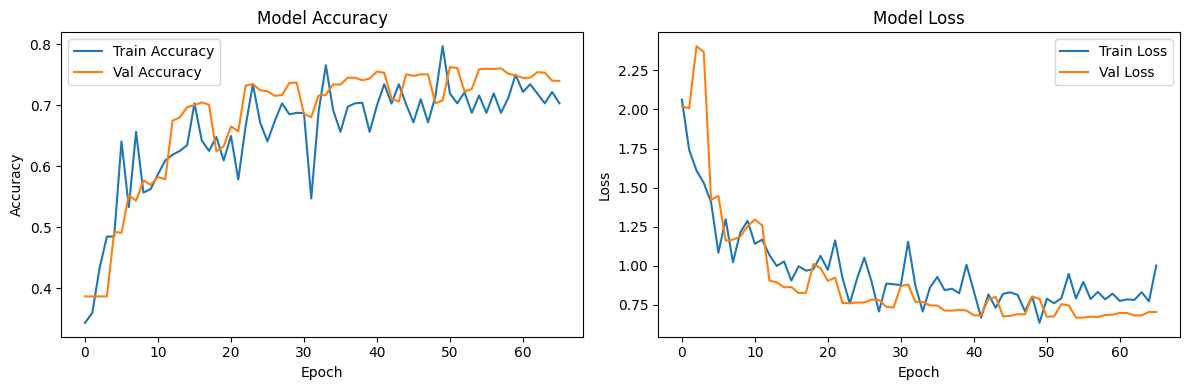

Training complete!


In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'],     label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'],     label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'training_history.png'))
plt.show()
print('Training complete!')